# 04 · Holdout Evaluation, Review Policy and Inference

The frozen notebook-trained artifact is evaluated through classification metrics, review-capacity constraints
and expected costs. Unlabeled test transactions receive calibrated risk scores and review actions.
Test labels are unavailable, so inference checks concern output integrity and policy compliance.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(
    path
    for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "src" / "fraud_detection").is_dir()
)
sys.path.insert(0, str(ROOT / "src"))

In [2]:
from dataclasses import replace

from fraud_detection.config import Config
from fraud_detection.data import ID, TARGET, TIME

config = replace(
    Config.load(ROOT / "configs" / "default.yaml"),
    output_dir=str(ROOT / "artifacts" / "notebook" / "full"),
)
processed_dir = Path(config.processed_dir)
artifact_dir = Path(config.output_dir)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.2})


def read_json(name):
    return json.loads((artifact_dir / name).read_text())

In [3]:
%matplotlib inline

## 1. Holdout Model Comparison

Average precision reflects ranking under class imbalance, ROC-AUC summarizes discrimination,
and log loss and Brier score assess probability quality. Baseline comparisons establish
the improvement beyond class prevalence and a small-feature logistic model.

In [4]:
from fraud_detection.metrics import classification_metrics
from fraud_detection.policy import ReviewState, business_metrics, daily_top_k, online_review

metrics = read_json("metrics.json")
selection = read_json("selection.json")
holdout = pd.read_parquet(artifact_dir / "holdout_predictions.parquet")
labels = holdout[TARGET].to_numpy()
scores = holdout.risk_score.to_numpy()
recomputed = classification_metrics(labels, scores)
assert np.isclose(
    recomputed["average_precision"], metrics["lightgbm_calibrated"]["average_precision"]
)
names = ["prior_baseline", "logistic_baseline", "lightgbm_raw", "lightgbm_calibrated"]
display(
    pd.DataFrame({name: metrics[name] for name in names}).T[
        ["average_precision", "roc_auc", "log_loss", "brier_score"]
    ]
)

,average_precision,roc_auc,log_loss,brier_score
prior_baseline,0.035046,0.500000,0.151868,0.033818
logistic_baseline,0.193954,0.760704,0.132081,0.031193
lightgbm_raw,0.538370,0.896581,0.102554,0.022283
lightgbm_calibrated,0.538370,0.896581,0.092972,0.021965


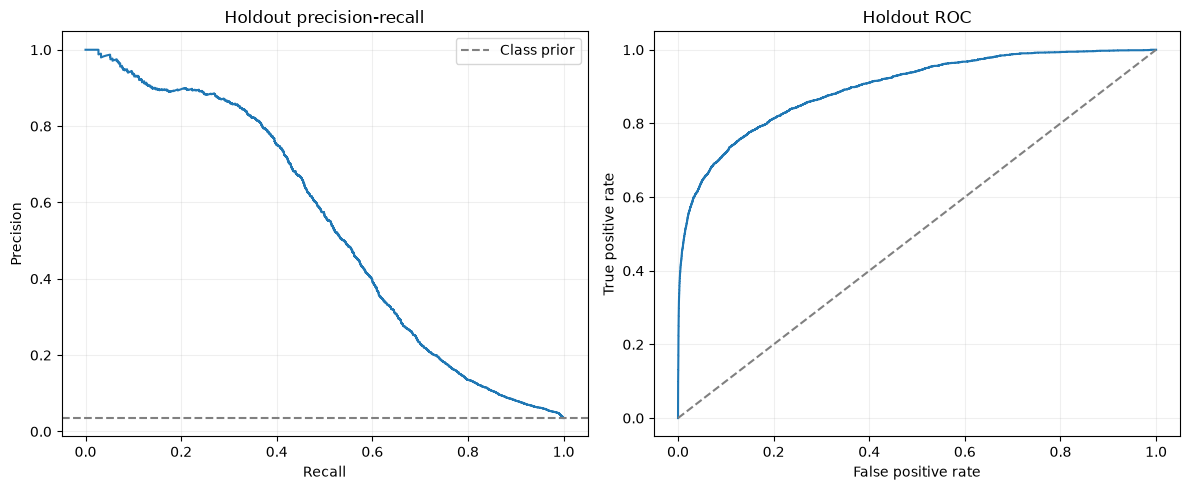

In [5]:
from sklearn.metrics import precision_recall_curve, roc_curve

precision, recall, _ = precision_recall_curve(labels, scores)
fpr, tpr, _ = roc_curve(labels, scores)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(recall, precision)
axes[0].axhline(labels.mean(), color="grey", linestyle="--", label="Class prior")
axes[0].set(title="Holdout precision-recall", xlabel="Recall", ylabel="Precision")
axes[0].legend()
axes[1].plot(fpr, tpr)
axes[1].plot([0, 1], [0, 1], color="grey", linestyle="--")
axes[1].set(title="Holdout ROC", xlabel="False positive rate", ylabel="True positive rate")
plt.tight_layout()
plt.show()

## 2. Online Review Allocation

After n transactions within a relative day, cumulative reviews cannot exceed floor(0.01 × n).
Events follow (TransactionDT, TransactionID) order and require a score above the frozen threshold.
This policy enforces capacity without future daily volume, although it may miss early fraud or leave capacity unused.

,day,transactions,frauds,reviews,review_rate,fraud_in_review
0,153,3105,126.0,30,0.009662,28.0
1,154,3783,94.0,20,0.005287,15.0
2,155,3352,119.0,24,0.007160,13.0
3,156,2575,54.0,21,0.008155,19.0
4,157,2259,69.0,10,0.004427,10.0
5,158,3048,81.0,20,0.006562,15.0
6,159,2845,89.0,26,0.009139,19.0
7,160,2878,85.0,25,0.008687,24.0
8,161,2854,68.0,26,0.009110,21.0
9,162,3233,114.0,29,0.008970,23.0


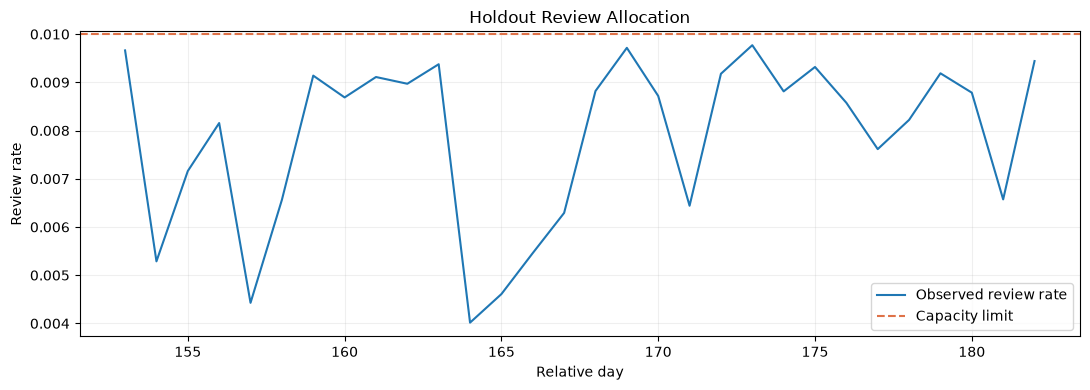

In [6]:
reviewed = online_review(holdout, scores, selection["threshold"], config.review_rate)
np.testing.assert_array_equal(reviewed, holdout.manual_review.to_numpy())
ordered = holdout.sort_values([TIME, ID]).copy()
days = ordered[TIME] // 86400
seen = ordered.groupby(days).cumcount() + 1
reviews_so_far = ordered.manual_review.groupby(days).cumsum()
assert (reviews_so_far <= np.floor(config.review_rate * seen + 1e-12)).all()

daily = pd.read_csv(artifact_dir / "daily_policy.csv")
display(daily.head(10))
fig, ax = plt.subplots()
daily.plot(x="day", y="review_rate", ax=ax, label="Observed review rate")
ax.axhline(config.review_rate, color="#df7248", linestyle="--", label="Capacity limit")
ax.set(title="Holdout Review Allocation", xlabel="Relative day", ylabel="Review rate")
ax.legend()
plt.tight_layout()
plt.show()

## 3. State Continuity Across Batches

ReviewState retains the current day, observed transaction count and allocated reviews.
Chronological batches share this state, making their combined decisions equivalent
to processing the same event stream in one batch.

In [7]:
state = ReviewState()
cut = len(holdout) // 2
first = online_review(
    holdout.iloc[:cut],
    scores[:cut],
    selection["threshold"],
    config.review_rate,
    state,
)
second = online_review(
    holdout.iloc[cut:],
    scores[cut:],
    selection["threshold"],
    config.review_rate,
    state,
)
np.testing.assert_array_equal(np.r_[first, second], reviewed)
display(pd.Series({"batch_equivalence": True, "prefix_quota_valid": True}))

batch_equivalence     True
prefix_quota_valid    True
dtype: bool

## 4. Expected Costs and Retrospective Benchmark

Review precision measures fraud concentration among selected transactions; review recall measures the share
of all fraud reaching review. Expected prevention additionally depends on reviewer sensitivity.
Daily top-k uses all scores from a completed day and therefore serves only as a retrospective benchmark.

In [8]:
retrospective = daily_top_k(holdout, scores, config.review_rate)
cost_args = (config.fraud_loss, config.review_cost, config.review_sensitivity)
comparison = pd.DataFrame(
    {
        "online": business_metrics(labels, reviewed, *cost_args),
        "daily_top_k_retrospective": business_metrics(labels, retrospective, *cost_args),
    }
).T
display(
    comparison[
        [
            "reviews",
            "review_rate",
            "fraud_in_review",
            "review_precision",
            "review_recall",
            "expected_prevented_frauds",
            "no_review_cost",
            "expected_cost",
            "expected_savings",
        ]
    ]
)
sensitivity = pd.read_csv(artifact_dir / "cost_sensitivity.csv")
display(
    sensitivity.pivot(
        index="review_sensitivity",
        columns="fraud_loss",
        values="expected_savings",
    )
)

,reviews,review_rate,fraud_in_review,review_precision,review_recall,expected_prevented_frauds,no_review_cost,expected_cost,expected_savings
online,670.0,0.007843,559.0,0.834328,0.186707,447.2,299400.0,255350.0,44050.0
daily_top_k_retrospective,838.0,0.009809,699.0,0.834129,0.233467,559.2,299400.0,244318.0,55082.0


fraud_loss,50,100,200
review_sensitivity,,,
0.5,13305.0,27280.0,55230.0
0.8,21690.0,44050.0,88770.0
1.0,27280.0,55230.0,111130.0


## 5. Feature Importance and Holdout Drift

Split gain describes the classifier's use of predictors rather than causal effects.
Population stability index compares monitored distributions with the calibration reference.
A PSI threshold of 0.2 is an investigation heuristic; a low value does not establish stable predictive performance.

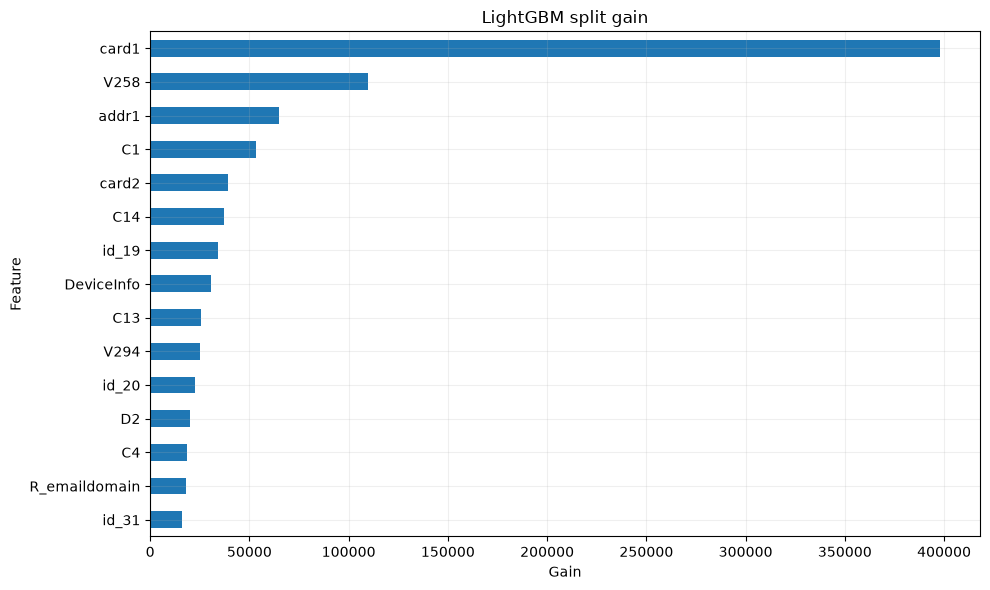

,feature,psi,reference_missing_rate,current_missing_rate,investigate
0,card4,0.079455,0.000000,0.008709,False
1,D1,0.033006,0.010511,0.000480,False
2,ProductCD,0.014298,0.000000,0.000000,False
3,DeviceType,0.009040,0.828520,0.791806,False
4,C13,0.003785,0.000000,0.000000,False
5,P_emaildomain,0.002744,0.164373,0.179586,False
6,C1,0.002436,0.000000,0.000000,False
7,risk_score,0.001791,0.000000,0.000000,False
8,TransactionAmt,0.001527,0.000000,0.000000,False


In [9]:
importance = pd.read_csv(artifact_dir / "feature_importance.csv")
fig, ax = plt.subplots(figsize=(10, 6))
importance.head(15).iloc[::-1].plot.barh(x="feature", y="gain", ax=ax, legend=False)
ax.set(title="LightGBM split gain", xlabel="Gain", ylabel="Feature")
plt.tight_layout()
plt.show()

drift = pd.read_csv(artifact_dir / "drift_holdout.csv")
display(drift.sort_values("psi", ascending=False))

## 6. Unlabeled Inference and Submission Integrity

Batch inference applies the frozen feature mappings, classifier, calibrator and online review policy.
Submission probabilities remain aligned with sample_submission transaction order.
Finite probabilities, unique identifiers and cumulative quota compliance establish output consistency,
without implying measured classification quality on unlabeled data.

In [10]:
from fraud_detection.inference import predict

predictions = predict(config)
submission = pd.read_csv(artifact_dir / "submission.csv")
sample = pd.read_csv(Path(config.raw_dir) / "sample_submission.csv", usecols=[ID])
assert submission.columns.tolist() == [ID, TARGET]
assert submission[ID].equals(sample[ID])
assert submission[ID].is_unique
assert np.isfinite(submission[TARGET]).all() and submission[TARGET].between(0, 1).all()
assert len(predictions) == len(submission)
ordered_test = predictions.sort_values([TIME, ID])
test_days = ordered_test[TIME] // 86400
test_seen = ordered_test.groupby(test_days).cumcount() + 1
test_reviews = ordered_test.manual_review.groupby(test_days).cumsum()
assert (test_reviews <= np.floor(config.review_rate * test_seen + 1e-12)).all()
display(submission.head())
display(
    pd.Series(
        {
            "test_rows": len(submission),
            "reviews": int(predictions.manual_review.sum()),
            "submission_order_valid": True,
            "test_prefix_quota_valid": True,
        }
    )
)
display(pd.read_csv(artifact_dir / "drift_test.csv").sort_values("psi", ascending=False))

,TransactionID,isFraud
0,3663549,0.000168
1,3663550,0.003256
2,3663551,0.000572
3,3663552,0.000528
4,3663553,0.002336


test_rows                  506691
reviews                      3515
submission_order_valid       True
test_prefix_quota_valid      True
dtype: object

,feature,psi,reference_missing_rate,current_missing_rate,investigate
0,C13,0.101807,0.000000,0.009371,False
1,ProductCD,0.068590,0.000000,0.000000,False
2,card4,0.060820,0.000000,0.006090,False
3,DeviceType,0.059598,0.828520,0.729754,False
4,C1,0.024359,0.000000,0.000006,False
5,D1,0.014985,0.010511,0.011903,False
6,P_emaildomain,0.011051,0.164373,0.136557,False
7,TransactionAmt,0.006170,0.000000,0.000000,False
8,risk_score,0.000848,0.000000,0.000000,False


In [11]:
%matplotlib inline

## 7. Batch Score Consistency

Scoring a small transaction batch with the saved artifact reproduces its corresponding inference probabilities.
Review decisions depend on the full chronological state, so this probability comparison
is separate from a daily-capacity simulation.

In [12]:
import joblib
import pyarrow.parquet as pq

model = joblib.load(artifact_dir / "model.joblib")
batch = next(pq.ParquetFile(processed_dir / "test.parquet").iter_batches(batch_size=12)).to_pandas()
batch_scores = model.predict_proba(batch)
preview = batch[[ID, TIME, "TransactionAmt"]].copy()
preview["risk_score"] = batch_scores
saved_scores = predictions.set_index(ID).loc[preview[ID], "risk_score"].to_numpy()
np.testing.assert_allclose(batch_scores, saved_scores)
display(preview)

,TransactionID,TransactionDT,TransactionAmt,risk_score
0,3663549,18403224,31.95,0.000168
1,3663550,18403263,49.00,0.003256
2,3663551,18403310,171.00,0.000572
3,3663552,18403310,284.95,0.000528
4,3663553,18403317,67.95,0.002336
5,3663554,18403323,57.95,0.004564
6,3663555,18403350,87.00,0.007258
7,3663556,18403387,390.00,0.020486
8,3663557,18403405,103.95,0.000595
9,3663558,18403416,117.00,0.004556


## Operational Interpretation

Review precision, recall and expected savings depend on the actual allocation rate and the assumed reviewer sensitivity.
Financial outcomes remain simulations under the stated costs. Production applicability also depends on
point-in-time feature availability, label delay and review latency. Subsequent labels support renewed
assessment of calibration, fraud recall and realized costs.